# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

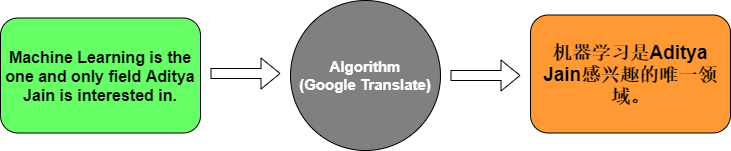

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [9]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.1429 - loss: 2.4830 - val_accuracy: 0.0000e+00 - val_loss: 2.4856
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5714 - loss: 2.4746 - val_accuracy: 0.0000e+00 - val_loss: 2.4876
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5714 - loss: 2.4659 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5714 - loss: 2.4565 - val_accuracy: 0.0000e+00 - val_loss: 2.4921
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.5714 - loss: 2.4462 - val_accuracy: 0.0000e+00 - val_loss: 2.4946
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5714 - loss: 2.4345 - val_accuracy: 0.0000e+00 - val_loss: 2.4975
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5714 - loss: 2.4212 - val_accuracy: 0.0000e+00 - val_loss: 2.5007
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.5714 - loss: 2.4057 - val_accuracy: 0.0000e+00 

In [10]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. What does the **Embedding** layer do to a word index?
* The Embedding layer converts each word index into a dense numerical vector so that the neural network can understand and learn relationships between them.

3. What is the role of the **Encoder LSTM**?
* The Encoder LSTM reads the input sentence word by word and captures its meaning and context. It processes the sequence and produces hidden and cell states that summarize the information to pass to the decoder.

5. What does the **Decoder LSTM** do?
* The Decoder LSTM uses the information received from the encoder to generate the translated sentence. It predicts the next word one at a time until it produces the complete translation.

8. Why do we use softmax in the final layer?
* Softmax converts the model's output scores into probabilities for all words in the target vocabulary.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")

print("Path to dataset files:", path)

100%|██████████| 3.51M/3.51M [00:00<00:00, 4.32MB/s]

Extracting files...


Path to dataset files: C:\Users\kilwa\.cache\kagglehub\datasets\devicharith\language-translation-englishfrench\versions\2


In [20]:
!pip install keras

In [22]:
import numpy as np
import pandas as pd
import tensorflow as tf
import re

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from keras.preprocessing.sequence import pad_sequences
from keras.models import Model
from keras.layers import Input, Embedding, LSTM, Dense

In [23]:
df = pd.read_csv("eng_-french.csv")

print(df.head())
print(df.shape)
print(df.columns)

  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !
(175621, 2)
Index(['English words/sentences', 'French words/sentences'], dtype='object')


In [24]:
# Keep only the English and French columns
df = df.iloc[:, :2].dropna()

# Rename columns
df.columns = ["English", "French"]

# Convert to lowercase
df["English"] = df["English"].str.lower()
df["French"] = df["French"].str.lower()

# Remove unnecessary characters
def clean_text(text):
    text = re.sub(r"[^a-zA-ZÀ-ÿ0-9\s']", "", str(text))
    return text.strip()

df["English"] = df["English"].apply(clean_text)
df["French"] = df["French"].apply(clean_text)

# Add start and end tokens to French sentences
df["French"] = df["French"].apply(
    lambda x: "<start> " + x + " <end>"
)

print(df.head())

  English                  French
0      hi     <start> salut <end>
1     run     <start> cours <end>
2     run    <start> courez <end>
3     who       <start> qui <end>
4     wow  <start> ça alors <end>


In [29]:
# Use a smaller random sample
df_small = df.sample(n=30000, random_state=42).reset_index(drop=True)

# Limit vocabulary size
VOCAB_SIZE = 10000
MAX_LEN = 20

eng_tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<unk>"
)

fra_tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n',
    oov_token="<unk>"
)

eng_tokenizer.fit_on_texts(df_small["English"])
fra_tokenizer.fit_on_texts(df_small["French"])

encoder_sequences = eng_tokenizer.texts_to_sequences(df_small["English"])
decoder_sequences = fra_tokenizer.texts_to_sequences(df_small["French"])

eng_vocab_size = min(VOCAB_SIZE, len(eng_tokenizer.word_index) + 1)
fra_vocab_size = min(VOCAB_SIZE, len(fra_tokenizer.word_index) + 1)

encoder_input = pad_sequences(
    encoder_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

decoder_data = pad_sequences(
    decoder_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

decoder_input = decoder_data[:, :-1]
decoder_target = decoder_data[:, 1:]

print("Dataset size:", len(df_small))
print("English vocabulary:", eng_vocab_size)
print("French vocabulary:", fra_vocab_size)

Dataset size: 30000
English vocabulary: 7799
French vocabulary: 10000


In [30]:
X_train, X_test, decoder_train, decoder_test, y_train, y_test = train_test_split(
    encoder_input,
    decoder_input,
    decoder_target,
    test_size=0.2,
    random_state=42
)

In [31]:
latent_dim = 128

# Encoder
encoder_inputs = Input(shape=(MAX_LEN,))

encoder_embedding = Embedding(
    eng_vocab_size,
    latent_dim,
    mask_zero=True
)

encoder_lstm = LSTM(
    latent_dim,
    return_state=True
)

enc_emb = encoder_embedding(encoder_inputs)

_, state_h, state_c = encoder_lstm(enc_emb)

encoder_states = [state_h, state_c]


# Decoder
decoder_inputs = Input(shape=(MAX_LEN - 1,))

decoder_embedding = Embedding(
    fra_vocab_size,
    latent_dim,
    mask_zero=True
)

decoder_lstm = LSTM(
    latent_dim,
    return_sequences=True,
    return_state=True
)

dec_emb = decoder_embedding(decoder_inputs)

decoder_outputs, _, _ = decoder_lstm(
    dec_emb,
    initial_state=encoder_states
)

decoder_dense = Dense(
    fra_vocab_size,
    activation="softmax"
)

decoder_outputs = decoder_dense(decoder_outputs)

# Complete model
model = Model(
    [encoder_inputs, decoder_inputs],
    decoder_outputs
)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_6       │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_7       │ (None, 19)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 20, 128)   │    998,272 │ input_layer_6[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 20)        │          0 │ input_layer_6[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 19, 128)   │  1,280,000 │ input_layer_7[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_4 (LSTM)       │ [(None, 128),     │    131,584 │ embedding_2[0][0… │
│                     │ (None, 128),      │            │ not_equal_4[0][0] │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ [(None, 19, 128), │    131,584 │ embedding_3[0][0… │
│                     │ (None, 128),      │            │ lstm_4[0][1],     │
│                     │ (None, 128)]      │            │ lstm_4[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 19, 10000) │  1,290,000 │ lstm_5[0][0]      │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,831,440 (14.62 MB)

 Trainable params: 3,831,440 (14.62 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
from tensorflow.keras.callbacks import EarlyStopping

history = model.fit(
    [X_train, decoder_train],
    y_train,
    batch_size=128,
    epochs=10,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - accuracy: 0.4458 - loss: 3.1813 - val_accuracy: 0.4286 - val_loss: 3.5317
Epoch 2/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.4571 - loss: 3.0712 - val_accuracy: 0.4329 - val_loss: 3.4709
Epoch 3/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.4676 - loss: 2.9652 - val_accuracy: 0.4410 - val_loss: 3.4160
Epoch 4/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.4777 - loss: 2.8667 - val_accuracy: 0.4480 - val_loss: 3.3698
Epoch 5/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.4875 - loss: 2.7734 - val_accuracy: 0.4528 - val_loss: 3.3313
Epoch 6/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.4973 - loss: 2.6829 - val_accuracy: 0.4573 - val_loss: 3.2934
Epoch 7/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.5048 - loss: 2.5971 - val_accuracy: 0.4621 - val_loss: 3.2591
Epoch 8/10
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - accuracy: 0.5143 - loss: 2

In [40]:
loss, accuracy = model.evaluate(
    [X_test, decoder_test],
    y_test,
    verbose=1
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.4639 - loss: 3.1994
Test Loss: 3.1993958950042725
Test Accuracy: 0.4639197885990143


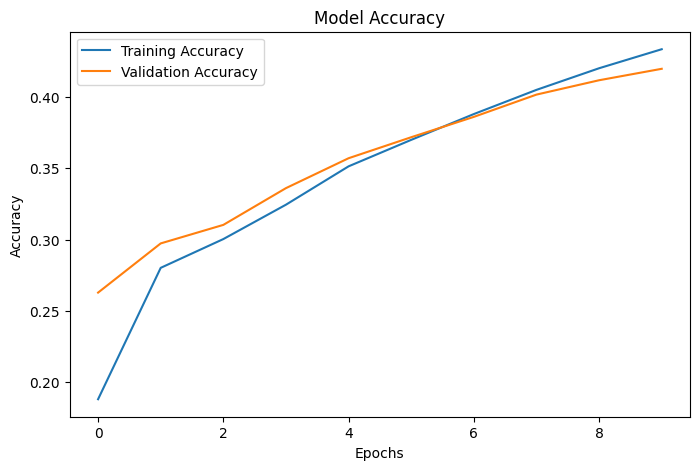

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.show()

In [35]:
# Encoder inference model
encoder_model = Model(
    encoder_inputs,
    encoder_states
)

# Decoder inference inputs
decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))

decoder_single_input = Input(shape=(1,))

decoder_emb2 = decoder_embedding(decoder_single_input)

decoder_outputs2, state_h2, state_c2 = decoder_lstm(
    decoder_emb2,
    initial_state=[decoder_state_input_h, decoder_state_input_c]
)

decoder_outputs2 = decoder_dense(decoder_outputs2)

decoder_model = Model(
    [decoder_single_input, decoder_state_input_h, decoder_state_input_c],
    [decoder_outputs2, state_h2, state_c2]
)

In [36]:
def translate_sentence(sentence):

    # Preprocess input
    sentence = clean_text(sentence)

    # Tokenize and pad
    sequence = eng_tokenizer.texts_to_sequences([sentence])

    sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Get encoder states
    states = encoder_model.predict(sequence, verbose=0)

    # Start token
    start_token = fra_tokenizer.word_index["<start>"]
    end_token = fra_tokenizer.word_index["<end>"]

    target_seq = np.array([[start_token]])

    translated_words = []

    for _ in range(MAX_LEN):

        output, state_h, state_c = decoder_model.predict(
            [target_seq] + states,
            verbose=0
        )

        predicted_id = np.argmax(output[0, -1, :])

        if predicted_id == end_token or predicted_id == 0:
            break

        word = fra_tokenizer.index_word.get(predicted_id, "")

        translated_words.append(word)

        target_seq = np.array([[predicted_id]])

        states = [state_h, state_c]

    return " ".join(translated_words)

In [37]:
test_sentence = "I love this product"

translation = translate_sentence(test_sentence)

print("English:", test_sentence)
print("French:", translation)

English: I love this product
French: j'aime le <unk>


In [38]:
model.save("english_french_translation.keras")

print("Model saved successfully!")

Model saved successfully!
